# Tema 1 - Introducere în Machine Learning
---

Import biblioteci si citire date

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import chi2_contingency
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from matplotlib.colors import LinearSegmentedColormap
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

# incarc fisierul de testare
df = pd.read_csv('CC_education_economy_train.csv')

## 3.1 Explorarea Datelor

1. Analiza tipului de atribute și a plajei de valori a acestora

In [2]:
# Tipurile de atribute
print('Tipuri de date')
print(df.dtypes)

# vad tipurile de date si dc am val lipsa
print(df.info())

# Atribute numerice
num_cols = ['experience_years', 'skills_count', 'certifications', 'total_days_worked', 'aggregated_score', 'salary']

# Atribute categorice
cat_cols = ['job_title', 'education_level', 'industry', 'company_size', 'location', 'remote_work', 'skill_bracket']

print(f'\nAtribute NUMERICE: {num_cols}')
print(f'Atribute CATEGORICE: {cat_cols}')

Tipuri de date
job_title                str
experience_years       int64
education_level          str
skills_count           int64
industry                 str
company_size             str
location                 str
remote_work              str
certifications         int64
salary                 int64
total_days_worked      int64
aggregated_score     float64
skill_bracket            str
vacation                 str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   job_title          64000 non-null  str    
 1   experience_years   64000 non-null  int64  
 2   education_level    64000 non-null  str    
 3   skills_count       64000 non-null  int64  
 4   industry           64000 non-null  str    
 5   company_size       64000 non-null  str    
 6   location           64000 non-null  str    
 7   remote_work        44847 non-n

Statistici pentru atribute numerice

,experience_years,skills_count,certifications,total_days_worked,aggregated_score,salary
count,64000.000,64000.000,64000.000,64000.000,64000.000,64000.000
mean,9.973,11.604,2.511,2393.508,0.001,145683.566
std,6.051,10.737,1.710,1452.045,1.000,37384.756
min,0.000,1.000,0.000,-1.000,-4.797,31867.000
25%,5.000,5.000,1.000,1200.000,-0.674,119209.750
50%,10.000,10.000,3.000,2400.000,0.001,143299.000
75%,15.000,15.000,4.000,3600.000,0.678,169582.250
max,20.000,69.000,5.000,4800.000,4.218,333046.000
valori_lipsa,0.000,0.000,0.000,0.000,0.000,0.000



    Grafice Boxplot pt atribute numerice 


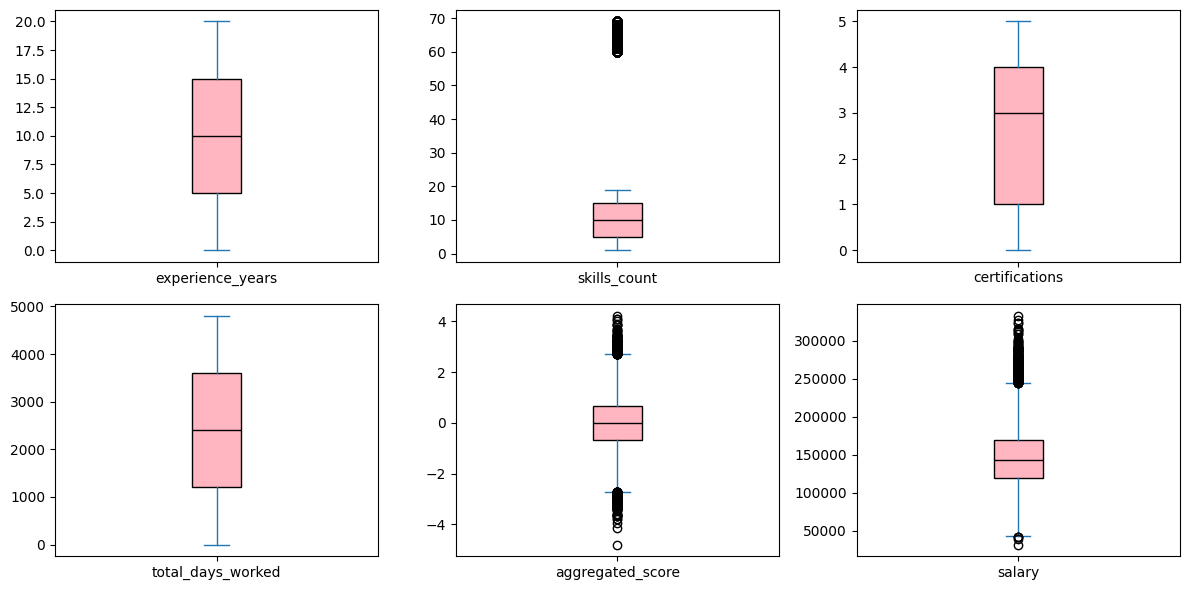

In [3]:
# Generez statisticile de baza: count, mean, std, min, 25%, 50%, 75%, max
stats_df = df[num_cols].describe().round(3)

# Cate val lipsa am pe fiecare coloana
missing_vals = df[num_cols].isna().sum()
stats_df.loc['valori_lipsa'] = missing_vals
display(stats_df)

# Cate un boxplot pt fiecare atribut numeric
print('\n    Grafice Boxplot pt atribute numerice ')
df[num_cols].plot(kind='box', subplots=True, layout=(2, 3), figsize=(12, 6), sharey=False,
    patch_artist=True, boxprops=dict(facecolor='lightpink', color='black'), medianprops=dict(color='black'))

plt.tight_layout()
plt.show()

Statistici atribute categoriale

,count-fara lipsa,valori unice,valori lipsa
job_title,64000,12,0
education_level,64000,5,0
industry,64000,10,0
company_size,64000,5,0
location,64000,10,0
remote_work,44847,3,19153
skill_bracket,64000,3,0



   Grafice histograma pt atribute categoriale 


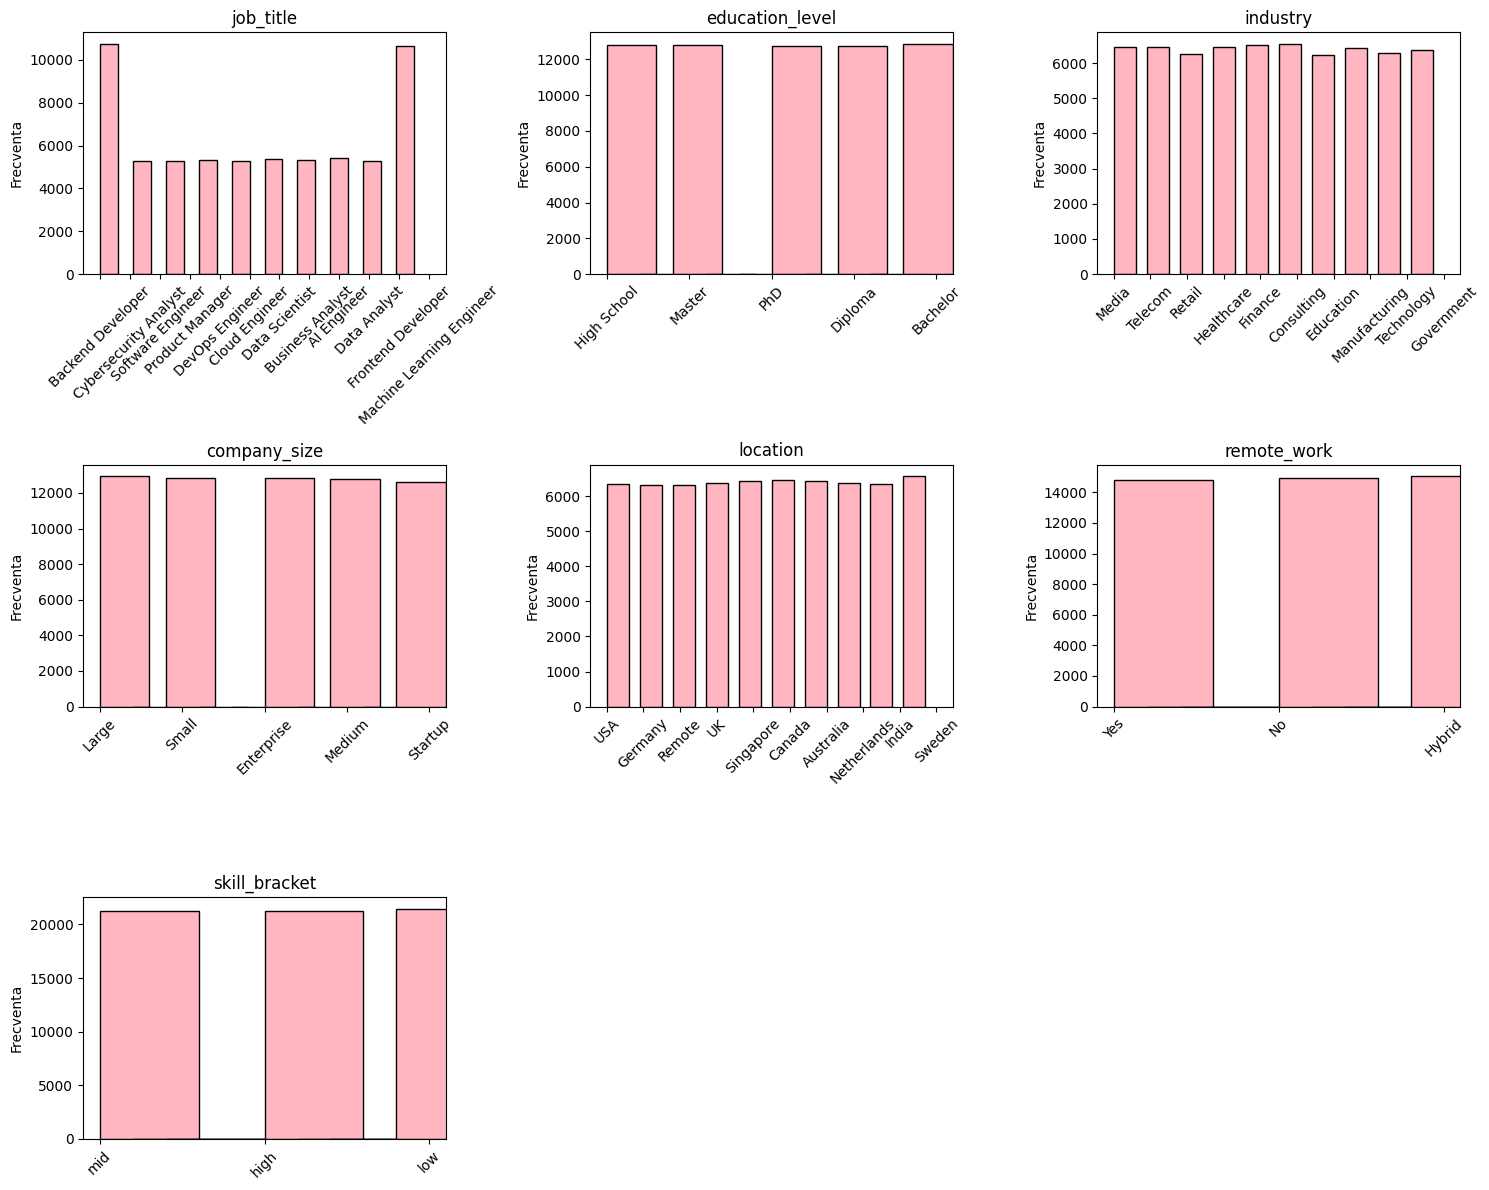

In [4]:
liste_valori_unice = []
for col in cat_cols:
    valori_gasite = pd.unique(df[col].dropna())
    liste_valori_unice.append(valori_gasite)

# Creez un nou data frame cu datele cerute
cat_stats = pd.DataFrame({'count-fara lipsa': df[cat_cols].count(),'valori unice':[len(lista) for lista in liste_valori_unice],'valori lipsa': df[cat_cols].isna().sum()})
display(cat_stats)

# Creez o figura pt a afisa toate histogramele
print('\n   Grafice histograma pt atribute categoriale ')
plt.figure(figsize=(15, 12))

for i, col in enumerate(cat_cols):
    plt.subplot(3, 3, i + 1)
    df[col].hist(width=0.6, color='lightpink', edgecolor='black', grid=False)
    plt.title(col)
    plt.xticks(rotation=45)
    plt.ylabel('Frecventa')
    plt.xlabel('')
plt.tight_layout()
plt.show()

2. Analiza echilibrului de clase 

Creare grafic pt clasa de clasificare - Vacation, si distributia pt regresie - Salary

vacation
No Vacation    34686
Small          12877
Medium          8527
Large           7910
Name: count, dtype: int64


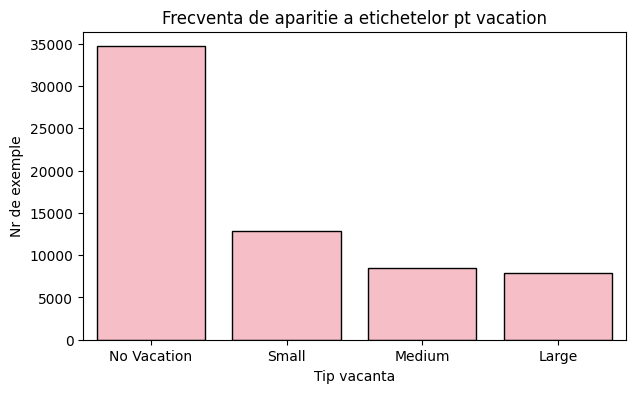

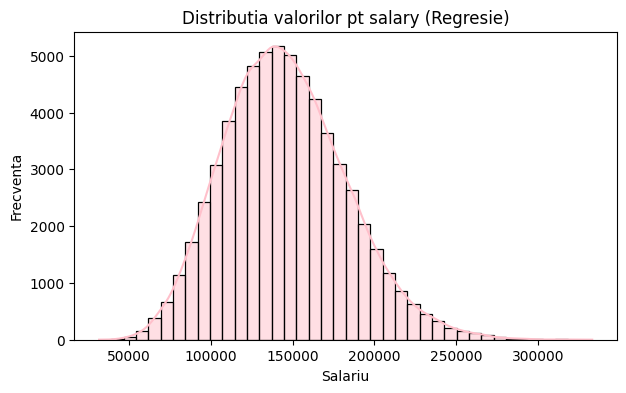

In [5]:
roz_vacation = '#FFB6C1' 
roz_salary = '#FFC0CB'   

# Afisez nr exacte pt raport
class_counts = df['vacation'].value_counts()
print(class_counts)

# Graficul pt Clasificare (vacation)
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='vacation', order=class_counts.index, color=roz_vacation, edgecolor='black')
plt.title('Frecventa de aparitie a etichetelor pt vacation')
plt.ylabel('Nr de exemple')
plt.xlabel('Tip vacanta')
plt.show()

# Graficul pt Regresie (salary)
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x='salary', bins=40, kde=True, color=roz_salary, edgecolor='black')
plt.title('Distributia valorilor pt salary (Regresie)')
plt.ylabel('Frecventa')
plt.xlabel('Salariu')
plt.show()

Set de date dezechilibrat -> Voi folosi metrici de Precizie, Recall si F1 pt evaluare corecta.

3. Analiza corelației între atribute  

Analiza corelatiei intre atribute



<Figure size 800x600 with 0 Axes>

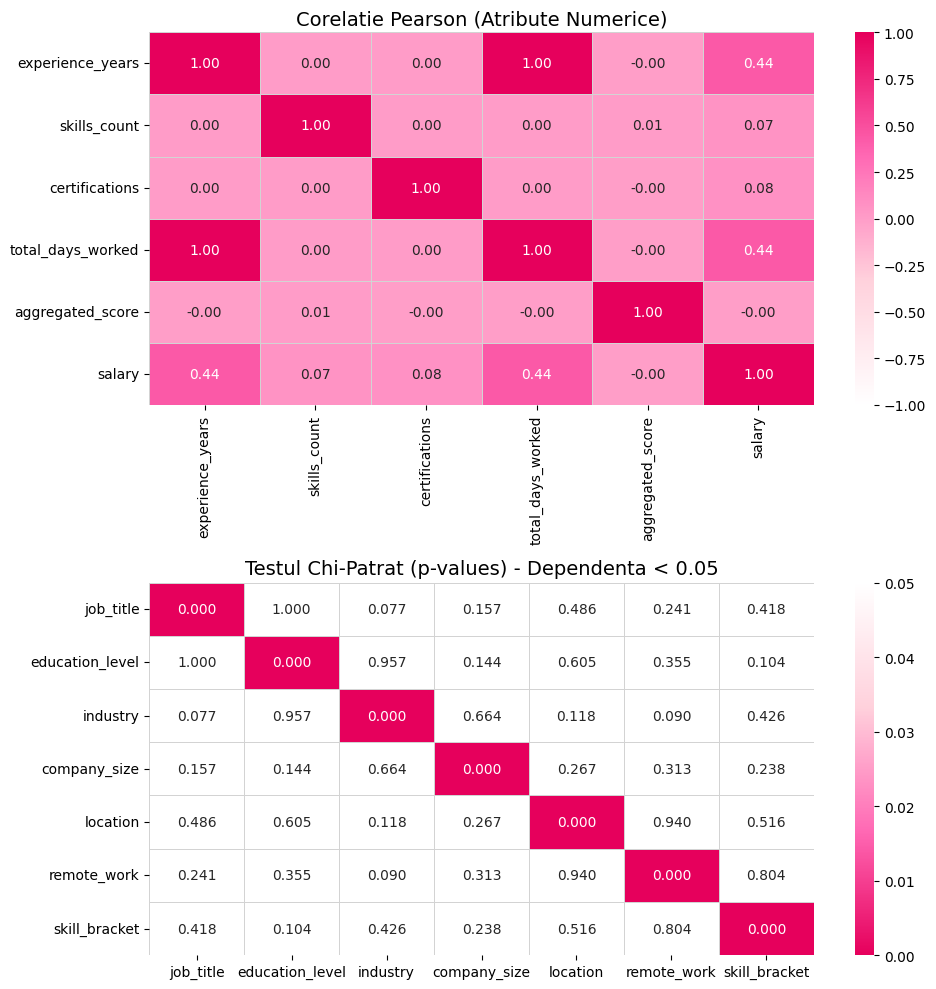


Verificarea redundantei intre atribute categorice (Chi-Patrat):
[job_title vs education_level] p-value: 0.9998 -> Independente
[job_title vs industry] p-value: 0.0767 -> Independente
[job_title vs company_size] p-value: 0.1566 -> Independente
[job_title vs location] p-value: 0.4865 -> Independente
[job_title vs remote_work] p-value: 0.2412 -> Independente
[job_title vs skill_bracket] p-value: 0.4177 -> Independente
[education_level vs industry] p-value: 0.9569 -> Independente
[education_level vs company_size] p-value: 0.1437 -> Independente
[education_level vs location] p-value: 0.6047 -> Independente
[education_level vs remote_work] p-value: 0.3550 -> Independente
[education_level vs skill_bracket] p-value: 0.1039 -> Independente
[industry vs company_size] p-value: 0.6637 -> Independente
[industry vs location] p-value: 0.1182 -> Independente
[industry vs remote_work] p-value: 0.0901 -> Independente
[industry vs skill_bracket] p-value: 0.4258 -> Independente
[company_size vs location]

In [6]:
print("Analiza corelatiei intre atribute\n")
culori_roz = ['#FFFFFF', '#FFD1DC', '#FF69B4', '#E6005C']
cmap_roz = LinearSegmentedColormap.from_list('RozCustom', culori_roz)
cmap_roz_inversat = LinearSegmentedColormap.from_list('RozCustom_r', culori_roz[::-1])

# Corelatia intre atributele numerice continue (Pearson)
plt.figure(figsize=(8, 6))

# Matricea Pearson
corr_matrix = df[num_cols].corr()

# Matricea Chi-Patrat pt atribute categorice
chi2_matrix = pd.DataFrame(np.zeros((len(cat_cols), len(cat_cols))), index=cat_cols, columns=cat_cols)

# Umplu matricea cu p-values
for col1 in cat_cols:
    for col2 in cat_cols:
        if col1 == col2:
            chi2_matrix.loc[col1, col2] = 0.000 # O variabila e perfect dependenta de ea insasi
        else:
            crosstab = pd.crosstab(df[col1].dropna(), df[col2].dropna())
            chi2, p_val, dof, ex = chi2_contingency(crosstab)
            chi2_matrix.loc[col1, col2] = p_val

fig, axes = plt.subplots(2, 1, figsize=(10, 10))
sns.heatmap(corr_matrix, annot=True, cmap=cmap_roz, fmt='.2f', vmin=-1, vmax=1, ax=axes[0],linewidths=0.5, linecolor='lightgray')
axes[0].set_title('Corelatie Pearson (Atribute Numerice)', fontsize=14)

# Chi-Patrat (Aici pun vmin=0 si vmax=0.05 pt a scoate in evidenta dependentele)
sns.heatmap(chi2_matrix, annot=True, cmap=cmap_roz_inversat, fmt='.3f', vmin=0, vmax=0.05, ax=axes[1], linewidths=0.5, linecolor='lightgray')
axes[1].set_title('Testul Chi-Patrat (p-values) - Dependenta < 0.05', fontsize=14)
plt.tight_layout()
plt.show()
# Corelatia intre atributele categorice (Testul Chi-Patrat)
print("\nVerificarea redundantei intre atribute categorice (Chi-Patrat):")
# functie pt a verifica perechile
for i in range(len(cat_cols)):
    for j in range(i+1, len(cat_cols)):
        col1, col2 = cat_cols[i], cat_cols[j]
        # tabelul de contingenta
        crosstab = pd.crosstab(df[col1].dropna(), df[col2].dropna())
        chi2, p, dof, ex = chi2_contingency(crosstab)
        # Afisez doar dc p-value e 0.0 (adica sunt extrem de corelate/redundante) sau aproape de 0
        if p < 0.05:
             print(f"[{col1} vs {col2}] p-value: {p:.4f} -> Dependenta statistica")
        else:
             print(f"[{col1} vs {col2}] p-value: {p:.4f} -> Independente")

CERINȚA MINIMĂ - analiza între un atribut numeric și sarcina de clasificare, un atribut 
categorial și sarcina de clasificare, un atribut numeric și sarcina de regresie, un atribut 
categorial și sarcina de regresie 


Analize de corelatie


/tmp/ipykernel_3254/1795941729.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='job_title', y='salary', palette='pastel')


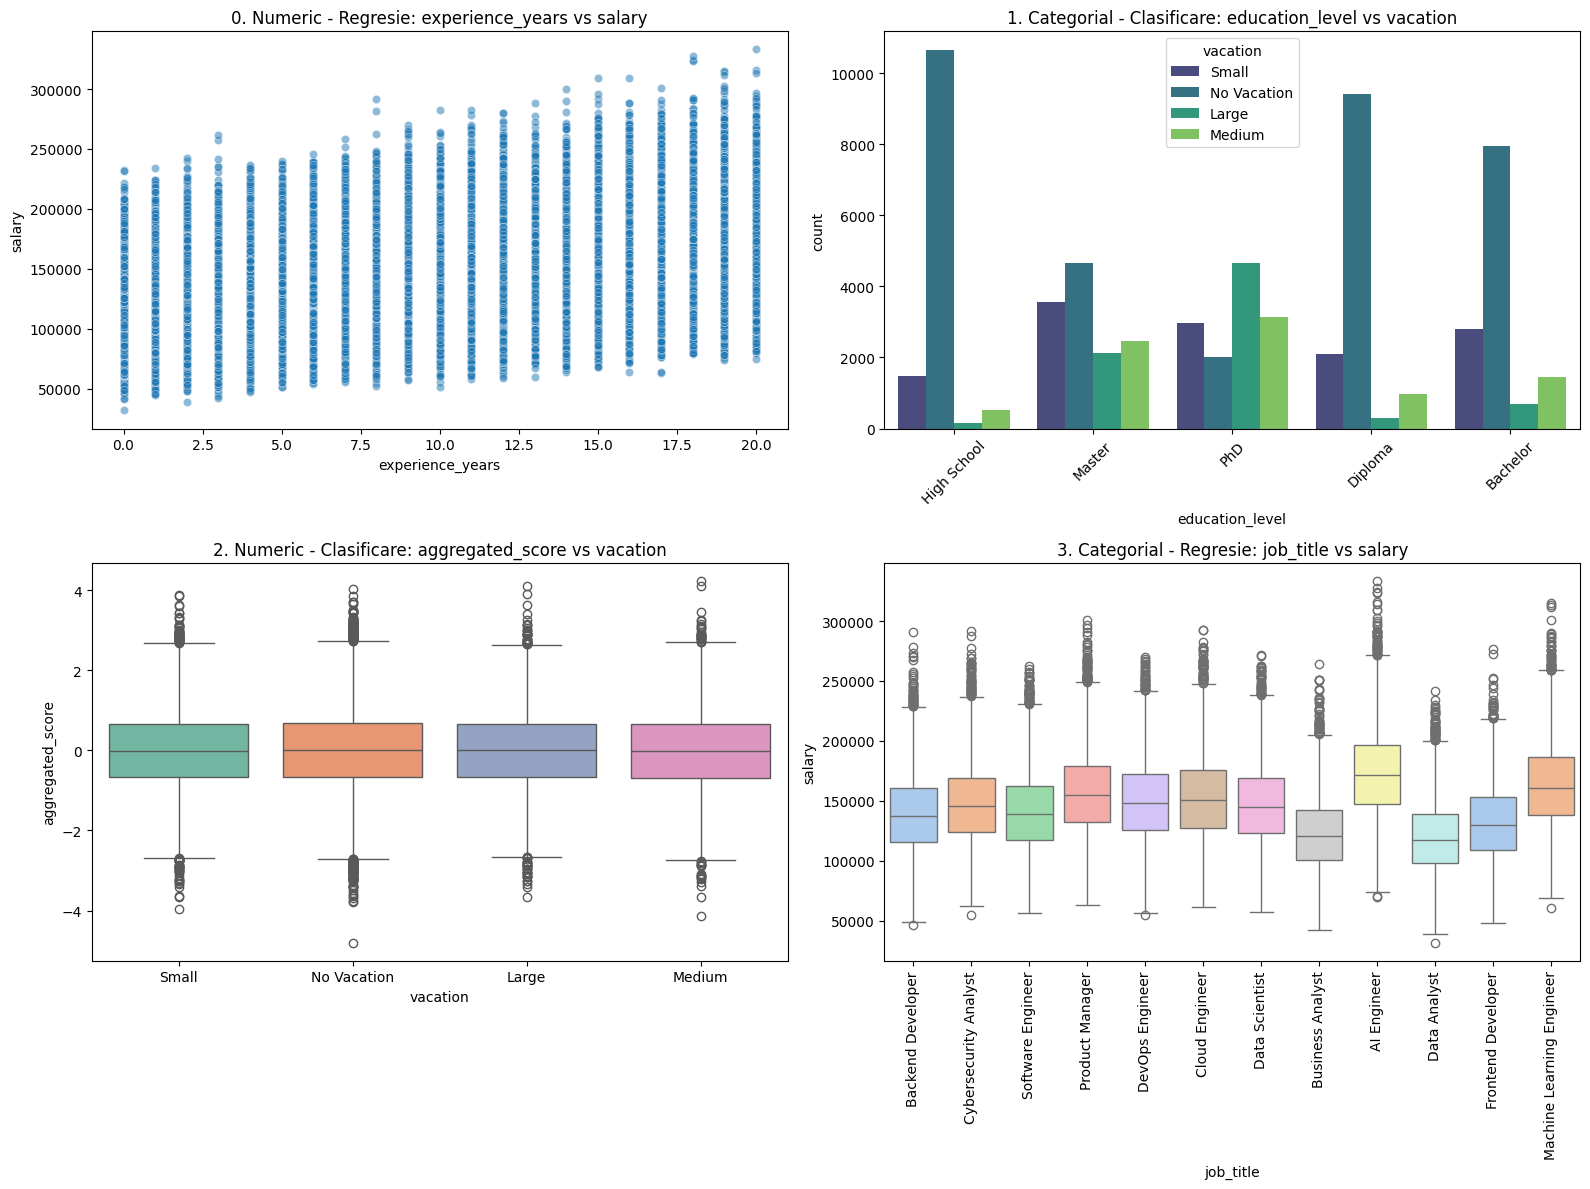

In [7]:
print('\nAnalize de corelatie')
plt.figure(figsize=(16, 12))

# 0. Numeric - Regresie: experience_years vs salary
plt.subplot(2, 2, 1)
sns.scatterplot(data=df, x='experience_years', y='salary', alpha=0.5, color='#1f77b4')
plt.title('0. Numeric - Regresie: experience_years vs salary')

# 1. Categorial - Clasificare: education_level vs vacation
plt.subplot(2, 2, 2)
sns.countplot(data=df, x='education_level', hue='vacation', palette='viridis')
plt.title('1. Categorial - Clasificare: education_level vs vacation')
plt.xticks(rotation=45)

# 2. Numeric - Clasificare: aggregated_score vs vacation
plt.subplot(2, 2, 3)
sns.boxplot(data=df, x='vacation', y='aggregated_score', hue='vacation', palette='Set2', legend=False)
plt.title('2. Numeric - Clasificare: aggregated_score vs vacation')

# 3. Categorial - Regresie: job_title vs salary
plt.subplot(2, 2, 4)
sns.boxplot(data=df, x='job_title', y='salary', palette='pastel')
plt.title('3. Categorial - Regresie: job_title vs salary')
plt.xticks(rotation=90) 

plt.tight_layout()
plt.show()

In [8]:
# pt afisarea tabelului, sa se vada bine
!pip install jinja2


[notice] A new release of pip is available: 26.0.1 -> 26.1
[notice] To update, run: pip install --upgrade pip


In [9]:
print("*Notă: Pentru analizele de tip mixt, variabilele numerice au fost discretizate in cuantile pt a permite aplicarea testului Chi-Patrat.\n")
rezultate = []

# 1. Numeric - Regresie (experience_years vs salary) -> PEARSON
scor_pearson = df['experience_years'].corr(df['salary'])
rezultate.append({
    'Relatie analizata': 'Numeric - Regresie (experience_years vs salary)',
    'Metoda': 'Pearson',
    'Rezultat (p-value / Scor)': f"{scor_pearson:.2f}",
    'Concluzie': 'Corelatie puternica; experienta este un factor determinant pentru salariu.'
})

# 2. Categorial - Clasificare (education_level vs vacation) -> CHI-PATRAT
crosstab_2 = pd.crosstab(df['education_level'], df['vacation'])
chi2, p_val_2, _, _ = chi2_contingency(crosstab_2)
rezultate.append({
    'Relatie analizata': 'Categorial - Clasificare (education_level vs vacation)',
    'Metoda': 'Chi-Patrat (χ²)',
    'Rezultat (p-value / Scor)': f"{p_val_2:.3f}",
    'Concluzie': 'p < 0.05: Exista o dependenta statistica semnificativa intre educatie si vacanta.'
})

# 3. Numeric - Clasificare (aggregated_score vs vacation) -> CHI-PATRAT cu discretizare
# Discretizez 'aggregated_score' in 4 categorii (cuantile)
score_categoric = pd.qcut(df['aggregated_score'], q=4, duplicates='drop')
crosstab_3 = pd.crosstab(score_categoric, df['vacation'])
chi2, p_val_3, _, _ = chi2_contingency(crosstab_3)
concluzie_3 = "p < 0.05: Exista o dependenta." if p_val_3 < 0.05 else "p > 0.05: Variabilele sunt independente; scorul nu influenteaza tipul de vacanta."
rezultate.append({'Relatie analizata': 'Numeric - Clasificare (aggregated_score vs vacation)','Metoda': 'Chi-Patrat (χ²)*',
    'Rezultat (p-value / Scor)': f"{p_val_3:.3f}",'Concluzie': concluzie_3})

# 4. Categorial - Regresie (job_title vs salary) -> CHI-PATRAT cu discretizare
# Discretizez 'salary' in 4 categorii (cuantile)
salary_categoric = pd.qcut(df['salary'], q=4, duplicates='drop')
crosstab_4 = pd.crosstab(df['job_title'], salary_categoric)
chi2, p_val_4, _, _ = chi2_contingency(crosstab_4)
concluzie_4 = "p < 0.05: Titlul jobului are o influenta majora asupra grilei de salarizare." if p_val_4 < 0.05 else "p > 0.05: Variabilele sunt independente."
rezultate.append({'Relatie analizata': 'Categorial - Regresie (job_title vs salary)', 'Metoda': 'Chi-Patrat (χ²)*',
    'Rezultat (p-value / Scor)': f"{p_val_4:.3f}",'Concluzie': concluzie_4})
tabel_final = pd.DataFrame(rezultate)
display(tabel_final.style.set_properties(**{'text-align': 'left'}))

*Notă: Pentru analizele de tip mixt, variabilele numerice au fost discretizate in cuantile pt a permite aplicarea testului Chi-Patrat.



,Relatie analizata,Metoda,Rezultat (p-value / Scor),Concluzie
0,Numeric - Regresie (experience_years vs salary),Pearson,0.44,Corelatie puternica; experienta este un factor determinant pentru salariu.
1,Categorial - Clasificare (education_level vs vacation),Chi-Patrat (χ²),0.000,p < 0.05: Exista o dependenta statistica semnificativa intre educatie si vacanta.
2,Numeric - Clasificare (aggregated_score vs vacation),Chi-Patrat (χ²)*,0.423,p > 0.05: Variabilele sunt independente; scorul nu influenteaza tipul de vacanta.
3,Categorial - Regresie (job_title vs salary),Chi-Patrat (χ²)*,0.000,p < 0.05: Titlul jobului are o influenta majora asupra grilei de salarizare.


## 3.2 Preprocesarea Datelor

1. Date lipsă pentru un atribut într-un eșantion

In [10]:
# Din 3.1 am extras ca remote_work are 19153 date lipsa, deci aplic imputarea pe coloana remote_work
imputer_cat = SimpleImputer(strategy='most_frequent')
df['remote_work'] = imputer_cat.fit_transform(df[['remote_work']]).ravel()

# Verific rezultatul
missing_after = df.isna().sum()
print("\nValori lipsa dupa imputare:")
print(missing_after[missing_after > 0] if missing_after.any() else "Nu mai exista!")


Valori lipsa dupa imputare:
Nu mai exista!


2. Valori extreme pentru un atribut într-un eșantion 

,experience_years,skills_count,certifications,total_days_worked,aggregated_score,salary
count,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000
mean,9.973391,11.604047,2.511141,2393.508219,0.000929,145683.565844
std,6.050682,10.737497,1.709811,1452.044678,0.999869,37384.755715
min,0.000000,1.000000,0.000000,-1.000000,-4.796902,31867.000000
25%,5.000000,5.000000,1.000000,1200.000000,-0.673757,119209.750000
50%,10.000000,10.000000,3.000000,2400.000000,0.001059,143299.000000
75%,15.000000,15.000000,4.000000,3600.000000,0.678273,169582.250000
max,20.000000,69.000000,5.000000,4800.000000,4.217828,333046.000000


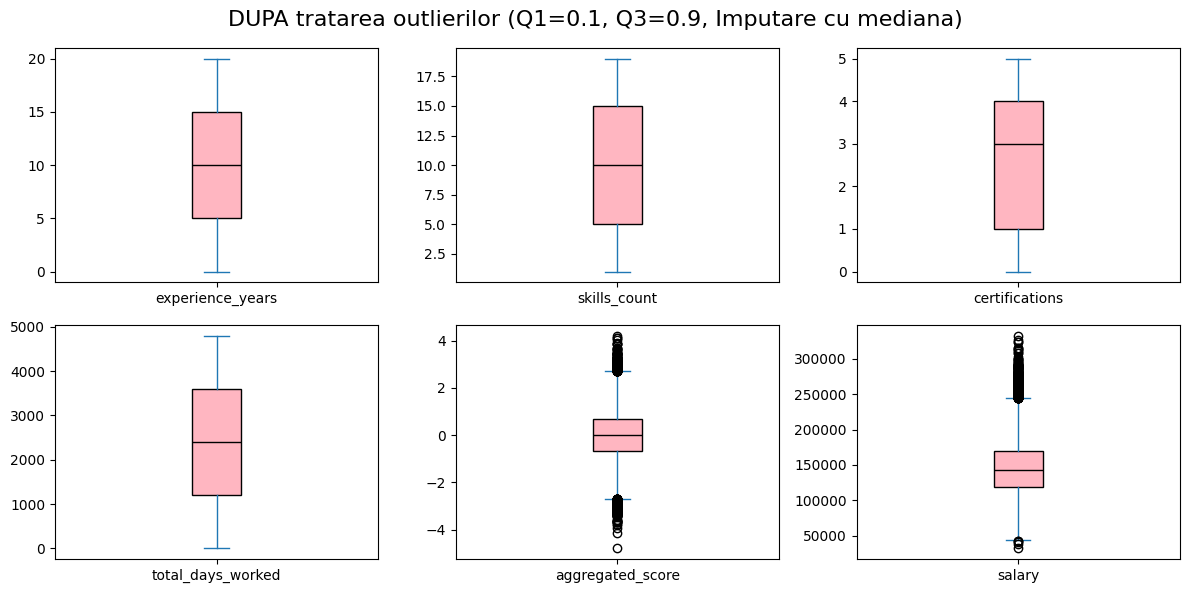

In [11]:

# Determinare valoril extreme 
display(df[num_cols].describe())

# Identificarea si inlocuirea outlierilor cu NaN pt fiecare coloana numerica
for col in num_cols:
    # Setez quantilele la valori extreme (0.1 si 0.9) pt a distinge anomaliile de val mari
    Q1 = df[col].quantile(0.1)
    Q3 = df[col].quantile(0.9)
    IQR = Q3 - Q1
    
    # Definesc limitele
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Gasesc outlierii
    outliers_mask = (df[col] < lower_bound) | (df[col] > upper_bound)
    nr_outliers = outliers_mask.sum()
    df.loc[outliers_mask, col] = np.nan

# Imputarea valorilor lipsa cu mediana
imputer_num = SimpleImputer(strategy='median')
df[num_cols] = imputer_num.fit_transform(df[num_cols])

# Vizualizare grafic dupa tratare
df[num_cols].plot(kind='box', subplots=True, layout=(2, 3), figsize=(12, 6), sharey=False, patch_artist=True, boxprops=dict(facecolor='lightpink', color='black'), medianprops=dict(color='black'))
plt.suptitle('DUPA tratarea outlierilor (Q1=0.1, Q3=0.9, Imputare cu mediana)', fontsize=16)
plt.tight_layout()
plt.show()

3. Atribute redundante (puternic corelate) 

In [12]:
print('Eliminare atributel redundante')

print("Coloane numerice inainte:", num_cols)

# Sterg coloana total_days_worked pe baza analizei de la 3.1
coloana_redundanta = 'total_days_worked'
if coloana_redundanta in df.columns:
    df = df.drop(columns=[coloana_redundanta])
    num_cols.remove(coloana_redundanta)

print("Coloane numerice ramase:", num_cols)

Eliminare atributel redundante
Coloane numerice inainte: ['experience_years', 'skills_count', 'certifications', 'total_days_worked', 'aggregated_score', 'salary']
Coloane numerice ramase: ['experience_years', 'skills_count', 'certifications', 'aggregated_score', 'salary']


4. Plaje valorice de mărimi diferite pentru atributele numerice

In [13]:
print("Datele inainte de standardizare")
num_cols_fara_target = [col for col in num_cols if col in df.columns and col != 'salary']
display(df[num_cols_fara_target].head(3))

scaler = StandardScaler()

# Aplic standardizarea pe coloanele numerice
df[num_cols_fara_target] = scaler.fit_transform(df[num_cols_fara_target])

print("\nDatele dupa standardizare")
display(df[num_cols_fara_target].head(3))

Datele inainte de standardizare


,experience_years,skills_count,certifications,aggregated_score
0,19.0,12.0,0.0,-0.723308
1,4.0,13.0,5.0,-0.481551
2,8.0,16.0,4.0,-1.533057



Datele dupa standardizare


,experience_years,skills_count,certifications,aggregated_score
0,1.491845,0.374969,-1.468677,-0.724337
1,-0.987234,0.560459,1.455646,-0.482547
2,-0.326146,1.116930,0.870781,-1.534198


## 3.3 Utilizarea algoritmilor de Învățare Automată 

Clasificare

In [14]:
print('Pregatire date pt clasificare')

# creez un set de date pt clasificare, scot salary pt ca e tinta de la regresie, nu ajuta la clasificare
df_class = df.drop(columns=['salary'])

# encodare variabila tinta
enc = LabelEncoder()
y = enc.fit_transform(df_class['vacation'])

# scot vacation din datele de antrenare
X = df_class.drop(columns=['vacation'])

# encodarea variabile categoriale predictor, transform textul in col cu 0 si 1, drop_first scapa de o col redundanta
X_encoded = pd.get_dummies(X, drop_first=True)

# impart datele in antrenare=80% si validare=20%, pe setul de validare voi testa metricile
X_train, X_val, y_train, y_val = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

print(f"Dimensiune X_train: {X_train.shape}")
print(f"Dimensiune X_val: {X_val.shape}")

Pregatire date pt clasificare
Dimensiune X_train: (51200, 45)
Dimensiune X_val: (12800, 45)


In [15]:
# Calculez toate metricile. Returnez un dictionar cu ele
def evalueaza_performanta(y_true, y_pred):   
    return {
        'Acuratete (↑)': accuracy_score(y_true, y_pred),
        'Precizie (↑)': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'Recall (↑)': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'F1 (↑)': f1_score(y_true, y_pred, average='weighted', zero_division=0)
    }

In [16]:
def evidentiaza_top2(row, max_val, sec_max_val):
    if row['F1 (↑)'] == max_val:
        return ['font-weight: bold'] * len(row)
    elif row['F1 (↑)'] == sec_max_val:
        return ['text-decoration: underline'] * len(row)
    else:
        return [''] * len(row)

In [17]:
# functie de antrenare, variez hiperparametrii: min_samples_leaf si max_depth
def antreneaza_si_evalueaza_dt(X_t, X_v, y_t, y_v, leaf_value=1, depth_value=None):
    model = DecisionTreeClassifier(min_samples_leaf=leaf_value, max_depth=depth_value, random_state=42)
    model.fit(X_t, y_t)
    preds = model.predict(X_v)
    metrici = evalueaza_performanta(y_v, preds)
    return {
        'Min_samples_leaf': leaf_value,
        'Max_depth': depth_value if depth_value else 'Nelimitat',
        **metrici
    }

print('\n   Clasificare DT - Ablatie pe 2 Hiperparametri')
rezultate_ablatie = [
    # 1. Baseline
    antreneaza_si_evalueaza_dt(X_train, X_val, y_train, y_val, leaf_value=1, depth_value=None),
    
    # 2. Experimentul 1: Variez doar frunzele
    antreneaza_si_evalueaza_dt(X_train, X_val, y_train, y_val, leaf_value=5, depth_value=None),
    antreneaza_si_evalueaza_dt(X_train, X_val, y_train, y_val, leaf_value=10, depth_value=None),
    antreneaza_si_evalueaza_dt(X_train, X_val, y_train, y_val, leaf_value=20, depth_value=None),
    antreneaza_si_evalueaza_dt(X_train, X_val, y_train, y_val, leaf_value=50, depth_value=None),
    antreneaza_si_evalueaza_dt(X_train, X_val, y_train, y_val, leaf_value=100, depth_value=None),
    antreneaza_si_evalueaza_dt(X_train, X_val, y_train, y_val, leaf_value=150, depth_value=None),

    # 3. Experimentul 2: Variez doar adancimea
    antreneaza_si_evalueaza_dt(X_train, X_val, y_train, y_val, leaf_value=1, depth_value=5),
    antreneaza_si_evalueaza_dt(X_train, X_val, y_train, y_val, leaf_value=1, depth_value=10),
    antreneaza_si_evalueaza_dt(X_train, X_val, y_train, y_val, leaf_value=1, depth_value=20),
    antreneaza_si_evalueaza_dt(X_train, X_val, y_train, y_val, leaf_value=1, depth_value=50)
]
tabel_ablatie = pd.DataFrame(rezultate_ablatie)

# Gasesc cele mai bune 2 valori unice pentru metrica F1
f1_unice_ablatie = tabel_ablatie['F1 (↑)'].drop_duplicates().nlargest(2).tolist()
max_f1_ablatie = f1_unice_ablatie[0]
sec_max_f1_ablatie = f1_unice_ablatie[1] if len(f1_unice_ablatie) > 1 else None

# Aplic stilizarea pe linie
tabel_ablatie_stilizat = tabel_ablatie.style.apply(
    evidentiaza_top2, 
    max_val=max_f1_ablatie, 
    sec_max_val=sec_max_f1_ablatie, 
    axis=1
).format(precision=3)
display(tabel_ablatie_stilizat)


   Clasificare DT - Ablatie pe 2 Hiperparametri


,Min_samples_leaf,Max_depth,Acuratete (↑),Precizie (↑),Recall (↑),F1 (↑)
0,1,Nelimitat,0.673,0.676,0.673,0.675
1,5,Nelimitat,0.706,0.699,0.706,0.702
2,10,Nelimitat,0.727,0.716,0.727,0.721
3,20,Nelimitat,0.738,0.727,0.738,0.731
4,50,Nelimitat,0.751,0.742,0.751,0.746
5,100,Nelimitat,0.751,0.743,0.751,0.747
6,150,Nelimitat,0.748,0.743,0.748,0.745
7,1,5,0.669,0.682,0.669,0.652
8,1,10,0.742,0.735,0.742,0.738
9,1,20,0.679,0.681,0.679,0.680


In [18]:
print('\n   Clasificare DT - Ablatie Combinata (Min_samples_leaf = 100 si Max_depth = 10)')
rezultate_combinate = []

# Experimentul 3: Fixez min_samples_leaf = 100 si variez max_depth
adancimi_de_testat = [5, 10, 15, 20, 50, None]
for adancime in adancimi_de_testat:
    rezultate_combinate.append(
        antreneaza_si_evalueaza_dt(X_train, X_val, y_train, y_val, leaf_value=100, depth_value=adancime)
    )

# Experimentul 4: Fixez max_depth = 10 si variez min_samples_leaf
frunze_de_testat = [1, 5, 20, 50, 150] 
for frunza in frunze_de_testat:
    rezultate_combinate.append(
        antreneaza_si_evalueaza_dt(X_train, X_val, y_train, y_val, leaf_value=frunza, depth_value=10)
    )

tabel_combinat = pd.DataFrame(rezultate_combinate)
# Sortez tabelul dupa metrica F1
tabel_combinat = tabel_combinat.sort_values(by='F1 (↑)', ascending=False).reset_index(drop=True)

# Gasesc cele mai bune 2 valori unice pentru metrica F1 din acest tabel
f1_unice_comb = tabel_combinat['F1 (↑)'].drop_duplicates().nlargest(2).tolist()
max_f1_comb = f1_unice_comb[0]
sec_max_f1_comb = f1_unice_comb[1] if len(f1_unice_comb) > 1 else None

# Aplic stilizarea
tabel_combinat_stilizat = tabel_combinat.style.apply(
    evidentiaza_top2, 
    max_val=max_f1_comb, 
    sec_max_val=sec_max_f1_comb, 
    axis=1
).format(precision=3)
display(tabel_combinat_stilizat)


   Clasificare DT - Ablatie Combinata (Min_samples_leaf = 100 si Max_depth = 10)


,Min_samples_leaf,Max_depth,Acuratete (↑),Precizie (↑),Recall (↑),F1 (↑)
0,100,15,0.751,0.743,0.751,0.747
1,100,50,0.751,0.743,0.751,0.747
2,100,20,0.751,0.743,0.751,0.747
3,100,Nelimitat,0.751,0.743,0.751,0.747
4,50,10,0.750,0.741,0.750,0.745
5,150,10,0.744,0.740,0.744,0.742
6,100,10,0.746,0.738,0.746,0.742
7,20,10,0.745,0.736,0.745,0.740
8,5,10,0.744,0.737,0.744,0.740
9,1,10,0.742,0.735,0.742,0.738


In [ ]:
print('\nTestare si comparare alte modele')

rezultate_avansate = []
# cel mai bun model (Arborele cu leaf=100)
dt_best = DecisionTreeClassifier(min_samples_leaf=100, random_state=42)
dt_best.fit(X_train, y_train)
rezultate_avansate.append({
    'Model': 'Decision Tree (Leaf=100)',
    'Configuratie': 'Baseline optimizat',
    **evalueaza_performanta(y_val, dt_best.predict(X_val))
})

# 2. Experimentez cu Random Forest (Ablatie pe nr de arbori)
nr_arbori = [10, 50, 100, 150]
for n in nr_arbori:
    rf = RandomForestClassifier(n_estimators=n, random_state=42)
    rf.fit(X_train, y_train)
    rezultate_avansate.append({
        'Model': 'Random Forest',
        'Configuratie': f'n_estimators={n}',
        **evalueaza_performanta(y_val, rf.predict(X_val))
    })

# 3. Experimentez cu Regresia Logistica
log_reg = LogisticRegression(max_iter=4000, random_state=42)
log_reg.fit(X_train, y_train)
rezultate_avansate.append({
    'Model': 'Logistic Regression',
    'Configuratie': 'Standard (Liniar)',
    **evalueaza_performanta(y_val, log_reg.predict(X_val))
})
tabel_perfectiune = pd.DataFrame(rezultate_avansate)

# Gasesc cele mai bune 2 valori unice pentru metrica F1 din acest al doilea tabel
f1_unice_perf = tabel_perfectiune['F1 (↑)'].drop_duplicates().nlargest(2).tolist()
max_f1_perf = f1_unice_perf[0]
sec_max_f1_perf = f1_unice_perf[1] if len(f1_unice_perf) > 1 else None

# Aplic stilizarea
tabel_perfectiune_stilizat = tabel_perfectiune.style.apply(
    evidentiaza_top2, 
    max_val=max_f1_perf, 
    sec_max_val=sec_max_f1_perf, 
    axis=1
).format(precision=3)
display(tabel_perfectiune_stilizat)


Testare si comparare alte modele


In [ ]:
# Numele claselor in ordinea lor (0, 1, 2, 3)
nume_clase = enc.inverse_transform([0, 1, 2, 3])

# Analiza per Clasa pentru Decision Tree
print(" Analiza per Clasa: Decision Tree (Leaf=100, Depth=15)")
dt_model = DecisionTreeClassifier(min_samples_leaf=100, max_depth=15, random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_val)
raport_dt = classification_report(y_val, y_pred_dt, target_names=nume_clase, zero_division=0)
print(raport_dt)
print("\n")

# Analiza per Clasa pentru Logistic Regression
print(" Analiza per Clasa: Logistic Regression")
lr_model = LogisticRegression(max_iter=4000, random_state=42)
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_val)
raport_lr = classification_report(y_val, y_pred_lr, target_names=nume_clase, zero_division=0)
print(raport_lr)

 Analiza per Clasa: Decision Tree (Leaf=100, Depth=15)
              precision    recall  f1-score   support

       Large       0.74      0.70      0.72      1556
      Medium       0.49      0.43      0.46      1708
 No Vacation       0.88      0.92      0.90      6989
       Small       0.54      0.53      0.54      2547

    accuracy                           0.75     12800
   macro avg       0.66      0.65      0.65     12800
weighted avg       0.74      0.75      0.75     12800



 Analiza per Clasa: Logistic Regression
              precision    recall  f1-score   support

       Large       0.74      0.76      0.75      1556
      Medium       0.53      0.38      0.45      1708
 No Vacation       0.88      0.93      0.90      6989
       Small       0.56      0.55      0.56      2547

    accuracy                           0.76     12800
   macro avg       0.68      0.66      0.66     12800
weighted avg       0.75      0.76      0.75     12800



EVALUAREA ALGORITMILOR DE CLASIFICARE



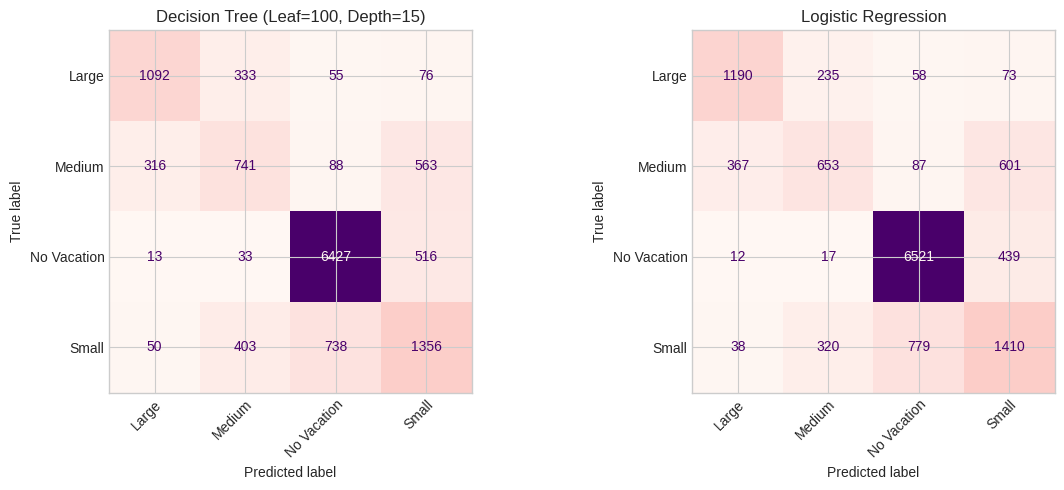

,Model,Acuratete,Precizie (Large),Recall (Large),F1 (Large),Precizie (Medium),Recall (Medium),F1 (Medium),Precizie (No Vacation),Recall (No Vacation),F1 (No Vacation),Precizie (Small),Recall (Small),F1 (Small)
0,"Decision Tree (Leaf=100, Depth=15)",0.751,0.742,0.702,0.722,0.491,0.434,0.461,0.879,0.920,0.899,0.540,0.532,0.536
1,Logistic Regression,0.764,0.741,0.765,0.752,0.533,0.382,0.445,0.876,0.933,0.904,0.559,0.554,0.556


In [ ]:
print('EVALUAREA ALGORITMILOR DE CLASIFICARE\n')

# Definesc cele mai bune modele gasite in etapa de experimentare
modele_clasificare = {
    'Decision Tree (Leaf=100, Depth=15)': DecisionTreeClassifier(min_samples_leaf=100, max_depth=15, random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=4000, random_state=42)
}

# Extrag numele claselor in ordinea lor (0, 1, 2, 3)
nume_clase = enc.inverse_transform([0, 1, 2, 3])

date_tabel = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Antrenez si evaluez fiecare model
for idx, (nume, model) in enumerate(modele_clasificare.items()):
    # Antrenarea se face pe X_train 
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    
    # Calculez metricile per clasa
    raport = classification_report(y_val, y_pred, target_names=nume_clase, output_dict=True, zero_division=0)
    
    # Construiesc randul pentru tabel
    rand_tabel = {'Model': nume, 'Acuratete': raport['accuracy']}
    for clasa in nume_clase:
        rand_tabel[f'Precizie ({clasa})'] = raport[clasa]['precision']
        rand_tabel[f'Recall ({clasa})'] = raport[clasa]['recall']
        rand_tabel[f'F1 ({clasa})'] = raport[clasa]['f1-score']
    date_tabel.append(rand_tabel)
    
    # Desenez Matricea de Confuzie
    cm = confusion_matrix(y_val, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nume_clase)
    disp.plot(ax=axes[idx], cmap='RdPu', colorbar=False)
    axes[idx].set_title(nume)
    plt.setp(axes[idx].get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

plt.tight_layout()
plt.show()

# tabel comparativ 
tabel_clase = pd.DataFrame(date_tabel)
def bold_max(s):
    is_max = s == s.max()
    return ['font-weight: bold' if v else '' for v in is_max]
tabel_final_stilizat = tabel_clase.style.apply(bold_max, subset=tabel_clase.columns[1:]).format(precision=3)
display(tabel_final_stilizat)

Regresie

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.utils import shuffle

# Pt regresie, tinta este salary. Deci scot obiectivul de la clasificare vacation
df_reg = df.drop(columns=['vacation'])
y_reg = df_reg['salary']
X_reg = df_reg.drop(columns=['salary'])

# Encodez predictorii categoriali ramasi
X_reg_encoded = pd.get_dummies(X_reg, drop_first=True)

# Impart datele (80% Train, 20% Val)
Xr_train, Xr_val, yr_train, yr_val = train_test_split(X_reg_encoded, y_reg, test_size=0.2, random_state=42)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

tabel_date = []

print("Linear Regression (No Regularization)")
lr = LinearRegression()
lr.fit(Xr_train, yr_train) 

# calcul rmse
pred_train_lr = lr.predict(Xr_train)
pred_val_lr = lr.predict(Xr_val)

rmse_train_lr = np.sqrt(mean_squared_error(yr_train, pred_train_lr))
rmse_val_lr = np.sqrt(mean_squared_error(yr_val, pred_val_lr))

print(f"Train RMSE: {rmse_train_lr:.2f}")
print(f"Validation RMSE: {rmse_val_lr:.2f}\n")
tabel_date.append({
    'Model': 'Linear Regression (Baseline)',
    'Regularization (α)': 'None',
    'Train RMSE (↓)': rmse_train_lr,
    'Validation RMSE (↓)': rmse_val_lr,
    'MAE': mean_absolute_error(yr_val, pred_val_lr),
    'MSE': mean_squared_error(yr_val, pred_val_lr),
    'R2': r2_score(yr_val, pred_val_lr)
})

print("Ridge regression (L2 Regularization)")

alphas = [0.1, 1, 10, 100, 1000]
for a in alphas:
    ridge = Ridge(alpha=a, random_state=42)
    ridge.fit(Xr_train, yr_train)
    
    p_train = ridge.predict(Xr_train)
    p_val = ridge.predict(Xr_val)
    
    tr_rmse = np.sqrt(mean_squared_error(yr_train, p_train))
    v_rmse = np.sqrt(mean_squared_error(yr_val, p_val))
    
    print(f"Alpha: {a:<6} | Train RMSE: {tr_rmse:.2f} | Val RMSE: {v_rmse:.2f}")
    tabel_date.append({
        'Model': 'Ridge Regression',
        'Regularization (α)': str(a),
        'Train RMSE (↓)': tr_rmse,
        'Validation RMSE (↓)': v_rmse,
        'MAE': mean_absolute_error(yr_val, p_val),
        'MSE': mean_squared_error(yr_val, p_val),
        'R2': r2_score(yr_val, p_val)
    })
print("\n")

# Generare tabel
df_tabel = pd.DataFrame(tabel_date)
df_tabel.set_index(['Model', 'Regularization (α)'], inplace=True)

def highlight_best(s):
    s_rounded = s.round(2)
    
    if s.name in ['MAE', 'MSE', 'RMSE', 'Train RMSE (↓)', 'Validation RMSE (↓)']:
        is_best = s_rounded == s_rounded.min()
    elif s.name == 'R2':
        is_best = s_rounded == s_rounded.max()
    else:
        is_best = [False] * len(s)
        
    return ['font-weight: bold' if v else '' for v in is_best]

print("Legenda: (↓) O valoare mai mica este mai buna.\n")
display(df_tabel[['Train RMSE (↓)', 'Validation RMSE (↓)', 'MAE', 'MSE', 'R2']].style.apply(highlight_best).format("{:.2f}"))

Linear Regression (No Regularization)
Train RMSE: 7343.87
Validation RMSE: 7390.99

Ridge regression (L2 Regularization)
Alpha: 0.1    | Train RMSE: 7343.87 | Val RMSE: 7391.01
Alpha: 1      | Train RMSE: 7343.91 | Val RMSE: 7391.27
Alpha: 10     | Train RMSE: 7347.99 | Val RMSE: 7397.40
Alpha: 100    | Train RMSE: 7618.60 | Val RMSE: 7681.86
Alpha: 1000   | Train RMSE: 11405.52 | Val RMSE: 11477.44


Legenda: (↓) O valoare mai mica este mai buna.



Calculăm pentru Regresia Liniară...


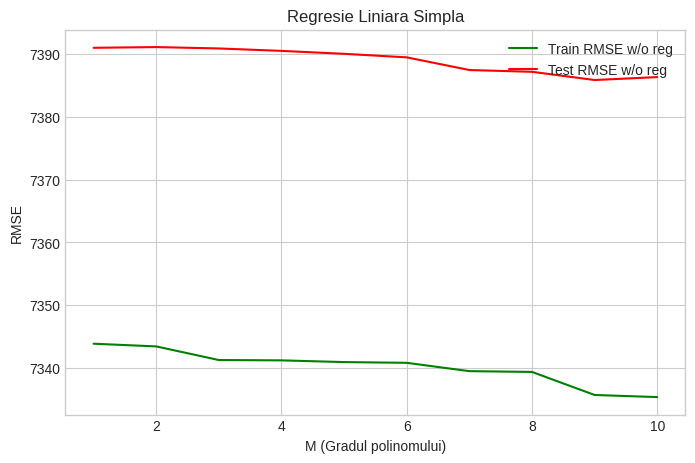

In [ ]:
# Experiment pentru Regresie Liniara fara regularizare
M_values = list(range(1, 11)) 
train_rmse_lin, test_rmse_lin = [], []
def get_polynomial_features(X, degree):
    X_arr = X.values if isinstance(X, pd.DataFrame) else X
    if degree == 1: 
        return X_arr
    features = [X_arr]
    # Ridic la putere element cu element
    for i in range(2, degree + 1):
        features.append(X_arr ** i)
    return np.hstack(features)

print("Calculez pentru Regresia Liniara...")
for M in M_values:
    X_tr_poly = get_polynomial_features(Xr_train, M)
    X_vl_poly = get_polynomial_features(Xr_val, M)
    
    scaler_poly = StandardScaler()
    X_tr_poly = scaler_poly.fit_transform(X_tr_poly)
    X_vl_poly = scaler_poly.transform(X_vl_poly)
    
    lr_poly = LinearRegression()
    lr_poly.fit(X_tr_poly, yr_train)
    
    train_rmse_lin.append(np.sqrt(mean_squared_error(yr_train, lr_poly.predict(X_tr_poly))))
    test_rmse_lin.append(np.sqrt(mean_squared_error(yr_val, lr_poly.predict(X_vl_poly))))

plt.figure(figsize=(8, 5))
plt.plot(M_values, train_rmse_lin, color="green", label="Train RMSE w/o reg")
plt.plot(M_values, test_rmse_lin, color="red", label="Test RMSE w/o reg")
plt.xlabel("M (Gradul polinomului)")
plt.ylabel("RMSE")
plt.title("Regresie Liniara Simpla")
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

Calculăm pentru Ridge (alpha=10)...


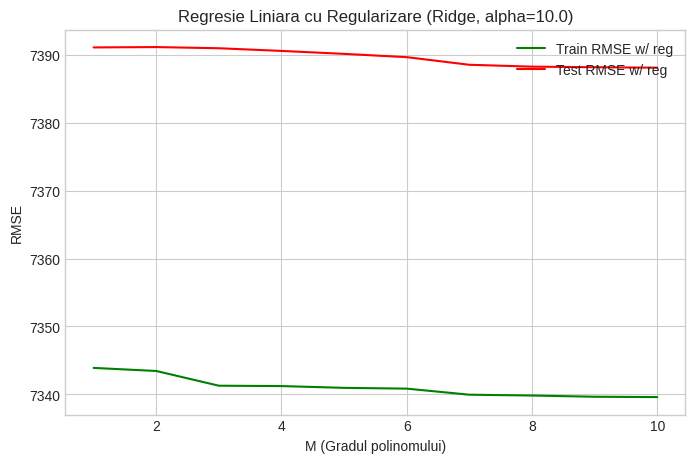

In [ ]:
# Experiment pentru Ridge cu regularizare L2
train_rmse_ridge, test_rmse_ridge = [], []
fixed_alpha = 10.0 

print("Calculez pentru Ridge (alpha=10)...")
for M in M_values:
    X_tr_poly = get_polynomial_features(Xr_train, M)
    X_vl_poly = get_polynomial_features(Xr_val, M)
    
    scaler_poly = StandardScaler()
    X_tr_poly = scaler_poly.fit_transform(X_tr_poly)
    X_vl_poly = scaler_poly.transform(X_vl_poly)
    
    rr_poly = Ridge(alpha=fixed_alpha, random_state=42)
    rr_poly.fit(X_tr_poly, yr_train)
    
    train_rmse_ridge.append(np.sqrt(mean_squared_error(yr_train, rr_poly.predict(X_tr_poly))))
    test_rmse_ridge.append(np.sqrt(mean_squared_error(yr_val, rr_poly.predict(X_vl_poly))))

plt.figure(figsize=(8, 5))
plt.plot(M_values, train_rmse_ridge, color="green", label="Train RMSE w/ reg")
plt.plot(M_values, test_rmse_ridge, color="red", label="Test RMSE w/ reg")
plt.xlabel("M (Gradul polinomului)")
plt.ylabel("RMSE")
plt.title(f"Regresie Liniara cu Regularizare (Ridge, alpha={fixed_alpha})")
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

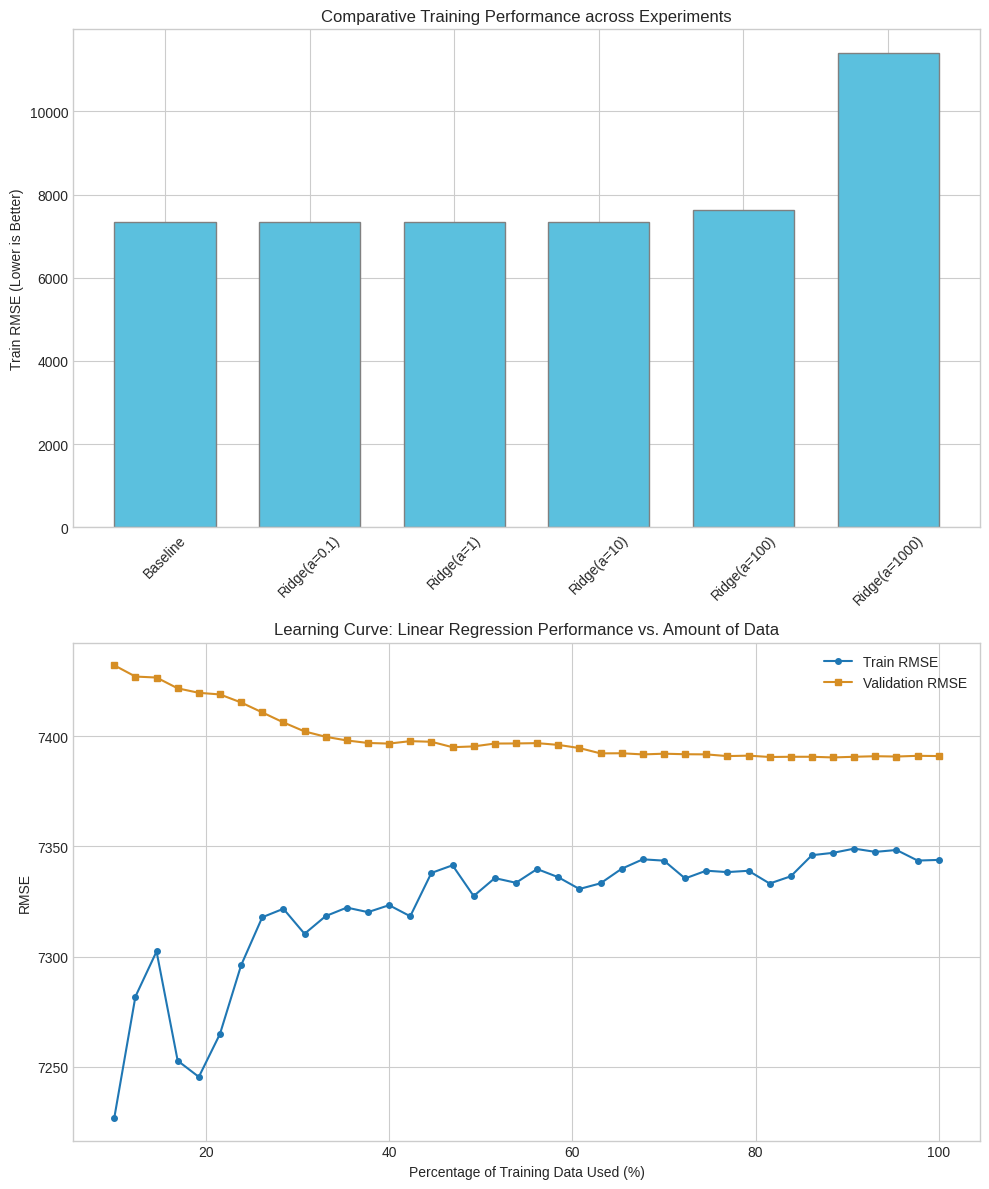

In [ ]:
import matplotlib.pyplot as plt
from sklearn.utils import shuffle

plt.style.use('seaborn-v0_8-whitegrid')
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 12))

etichete_modele = ['Baseline', 'Ridge(a=0.1)', 'Ridge(a=1)', 'Ridge(a=10)', 'Ridge(a=100)', 'Ridge(a=1000)']
train_rmses = df_tabel['Train RMSE (↓)'].tolist()

ax1.bar(etichete_modele, train_rmses, color='#5bc0de', edgecolor='gray', width=0.7)
ax1.set_title('Comparative Training Performance across Experiments', fontsize=12)
ax1.set_ylabel('Train RMSE (Lower is Better)')
ax1.tick_params(axis='x', rotation=45)


Xr_shuffled, yr_shuffled = shuffle(Xr_train, yr_train, random_state=42)

procente = np.linspace(0.1, 1.0, 40) 
train_rmse_lc = []
val_rmse_lc = []

lr_lc = LinearRegression()

for p in procente:
    limit = int(p * len(Xr_shuffled))
    X_subset = Xr_shuffled.iloc[:limit]
    y_subset = yr_shuffled.iloc[:limit]
    
    lr_lc.fit(X_subset, y_subset)
    
    train_rmse_lc.append(np.sqrt(mean_squared_error(y_subset, lr_lc.predict(X_subset))))
    val_rmse_lc.append(np.sqrt(mean_squared_error(yr_val, lr_lc.predict(Xr_val))))

x_axis_percentages = procente * 100

ax2.plot(x_axis_percentages, train_rmse_lc, marker='o', markersize=4, linestyle='-', color='#1f77b4', label='Train RMSE')
ax2.plot(x_axis_percentages, val_rmse_lc, marker='s', markersize=4, linestyle='-', color='#d68e24', label='Validation RMSE')
ax2.set_title('Learning Curve: Linear Regression Performance vs. Amount of Data', fontsize=12)
ax2.set_xlabel('Percentage of Training Data Used (%)')
ax2.set_ylabel('RMSE')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# 1. INCARCAREA DATELOR
df_train = pd.read_csv('CC_education_economy_train.csv')
df_test_public = pd.read_csv('CC_education_economy_test.csv') 

df_all = pd.concat([df_train, df_test_public], ignore_index=True)

fisier_kaggle = 'CC_private_test.csv' 
df_private = pd.read_csv(fisier_kaggle)

private_ids = df_private['id'].copy()

# 2. SEPARAREA VARIABILELOR SI PREGATIREA
num_cols = ['experience_years', 'skills_count', 'certifications', 'total_days_worked', 'aggregated_score']
cat_cols = ['job_title', 'education_level', 'industry', 'company_size', 'location', 'remote_work', 'skill_bracket']

# Variabila tinta o procesam separat
enc = LabelEncoder()
y_all = enc.fit_transform(df_all['vacation'])
X_all = df_all[num_cols + cat_cols].copy()
X_private = df_private[num_cols + cat_cols].copy()

# 3. TRATAREA VALORILOR LIPSA 
imputer_cat = SimpleImputer(strategy='most_frequent')
X_all[cat_cols] = imputer_cat.fit_transform(X_all[cat_cols])
X_private[cat_cols] = imputer_cat.transform(X_private[cat_cols])
imputer_num = SimpleImputer(strategy='median')
X_all[num_cols] = imputer_num.fit_transform(X_all[num_cols])
X_private[num_cols] = imputer_num.transform(X_private[num_cols])

# 4. ENCODARE 
X_all_encoded = pd.get_dummies(X_all, columns=cat_cols, drop_first=True)
X_private_encoded = pd.get_dummies(X_private, columns=cat_cols, drop_first=True)
X_private_encoded = X_private_encoded.reindex(columns=X_all_encoded.columns, fill_value=0)

# 5. STANDARDIZARE
scaler = StandardScaler()
X_all_scaled = scaler.fit_transform(X_all_encoded)
X_private_scaled = scaler.transform(X_private_encoded)

# 6. ANTRENAREA MODELULUI SI PREDICTIA
model = LogisticRegression(max_iter=4000, random_state=42)
model.fit(X_all_scaled, y_all)

predictii_cifre = model.predict(X_private_scaled)
predictii_text = enc.inverse_transform(predictii_cifre)

# 7. GENERARE FISIER SUBMISIE
submisie = pd.DataFrame({
    'id': private_ids,
    'prediction': predictii_text
})
submisie.to_csv('submisie_FINAL_LogisticReg.csv', index=False)

Generam predictiile pentru Kaggle...


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression

# 1. INCARCAREA DATELOR
df_train = pd.read_csv('CC_education_economy_train.csv')
df_test_public = pd.read_csv('CC_education_economy_test.csv') 
df_all = pd.concat([df_train, df_test_public], ignore_index=True)

# Fisierul privat de test pentru competitia de regresie
fisier_kaggle = 'CC_private_regresie.csv' 
df_private = pd.read_csv(fisier_kaggle)
private_ids = df_private['id'].copy()

# 2. SEPARAREA VARIABILELOR SI PREGATIREA
num_cols = ['experience_years', 'skills_count', 'certifications', 'total_days_worked', 'aggregated_score']
num_cols = [col for col in num_cols if col in df_all.columns]

cat_cols = ['job_title', 'education_level', 'industry', 'company_size', 'location', 'remote_work', 'skill_bracket']

# Variabila tinta pentru regresie este 'salary'
y_all = df_all['salary'].values

# Pregatesc predictorii (X)
X_all = df_all[num_cols + cat_cols].copy()
X_private = df_private[num_cols + cat_cols].copy()

# 3. TRATAREA VALORILOR LIPSA 
imputer_cat = SimpleImputer(strategy='most_frequent')
X_all[cat_cols] = imputer_cat.fit_transform(X_all[cat_cols])
X_private[cat_cols] = imputer_cat.transform(X_private[cat_cols])

imputer_num = SimpleImputer(strategy='median')
X_all[num_cols] = imputer_num.fit_transform(X_all[num_cols])
X_private[num_cols] = imputer_num.transform(X_private[num_cols])

# 4. ENCODARE CATEGORIALA (One-Hot Encoding)
X_all_encoded = pd.get_dummies(X_all, columns=cat_cols, drop_first=True)
X_private_encoded = pd.get_dummies(X_private, columns=cat_cols, drop_first=True)
X_private_encoded = X_private_encoded.reindex(columns=X_all_encoded.columns, fill_value=0)

# 5. STANDARDIZARE 
scaler = StandardScaler()
X_all_scaled = scaler.fit_transform(X_all_encoded)
X_private_scaled = scaler.transform(X_private_encoded)

# 6. ANTRENAREA MODELULUI SI PREDICTIA
model = LinearRegression()
model.fit(X_all_scaled, y_all)

predictii_salariu = model.predict(X_private_scaled)

# 7. GENERARE FISIER SUBMISIE
submisie = pd.DataFrame({
    'id': private_ids,
    'prediction': predictii_salariu
})

nume_fisier = 'submisie_FINAL_Regresie_Liniara.csv'
submisie.to_csv(nume_fisier, index=False)

Generam predictiile de salariu pentru Kaggle...
Succes! Fisierul 'submisie_FINAL_Regresie_Liniara.csv' a fost generat.
